# Lab 1: Data Visualization, Data Preprocessing, and Statistical Analysis Using Python in Jupyter Notebook

**Corey Hyde**  
**Student ID:** 003044072  
**Course:** MSCS-634-A01 — Advanced Big Data and Data Mining  
**Assignment:** Lab 1

**Dataset:** Synthetic retail sales transactions (2025). All observations are generated for educational purposes; results do not describe a real company.

**Objective:** Demonstrate data collection, six visualizations, missing-data treatment, outlier detection, sampling, feature scaling, age discretization, descriptive statistics, and correlation analysis. Run cells from top to bottom.

## Step 1 — Data collection

The dataset models 500 sales transactions across five product categories and four regions. A fixed seed makes the exercise reproducible. A small number of unusually large purchases and missing values are introduced intentionally to demonstrate preprocessing. The dependent field `Total_Sales` is always calculated as `Units_Sold × Unit_Price` when both inputs exist.

In [1]:
from pathlib import Path
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from IPython.display import display, Markdown

SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (9, 5.2), "axes.titlesize": 13, "axes.labelsize": 11})

# The notebook lives in the repository root. No absolute computer-specific paths.
DATA_DIR = Path("data")
SCREEN_DIR = Path("screenshots")
DATA_DIR.mkdir(exist_ok=True)
SCREEN_DIR.mkdir(exist_ok=True)

def save_chart(filename):
    plt.tight_layout()
    plt.savefig(SCREEN_DIR / filename, dpi=180, bbox_inches="tight")
    plt.show()

# These are evidence images of rendered tables, not a substitute for notebook screenshots.
def save_table(frame, filename, title, max_rows=16):
    shown = frame.head(max_rows).copy()
    shown = shown.reset_index()
    shown.columns = [str(c) for c in shown.columns]
    fig_h = max(2.2, 0.4 * (len(shown) + 2))
    fig, ax = plt.subplots(figsize=(min(18, max(9, len(shown.columns)*1.5)), fig_h))
    ax.axis("off")
    vals = shown.astype(str).values
    tab = ax.table(cellText=vals, colLabels=shown.columns, cellLoc="center", loc="center")
    tab.auto_set_font_size(False)
    tab.set_fontsize(8)
    tab.scale(1, 1.3)
    ax.set_title(title, pad=15)
    save_chart(filename)

SCREENSHOT 01 — First five rows


,Transaction_ID,Date,Product_Category,Product_Name,Units_Sold,Unit_Price,Total_Sales,Customer_Age,Customer_Region,Customer_Rating
0,TXN0001,2025-02-01,Sports,Dumbbells,4.0,83.07,332.28,57.0,North,3.2
1,TXN0002,2025-02-16,Sports,Yoga Mat,5.0,30.40,152.00,65.0,South,4.5
2,TXN0003,2025-07-19,Beauty,Face Serum,6.0,42.78,256.68,43.0,South,4.2
3,TXN0004,2025-08-19,Electronics,Headphones,3.0,97.75,293.25,27.0,West,3.6
4,TXN0005,2025-10-05,Beauty,Moisturizer,9.0,28.17,253.53,NaN,South,4.2


Shape: (500, 10)
Columns: ['Transaction_ID', 'Date', 'Product_Category', 'Product_Name', 'Units_Sold', 'Unit_Price', 'Total_Sales', 'Customer_Age', 'Customer_Region', 'Customer_Rating']
Data types:
Transaction_ID              object
Date                datetime64[ns]
Product_Category            object
Product_Name                object
Units_Sold                 float64
Unit_Price                 float64
Total_Sales                float64
Customer_Age               float64
Customer_Region             object
Customer_Rating            float64


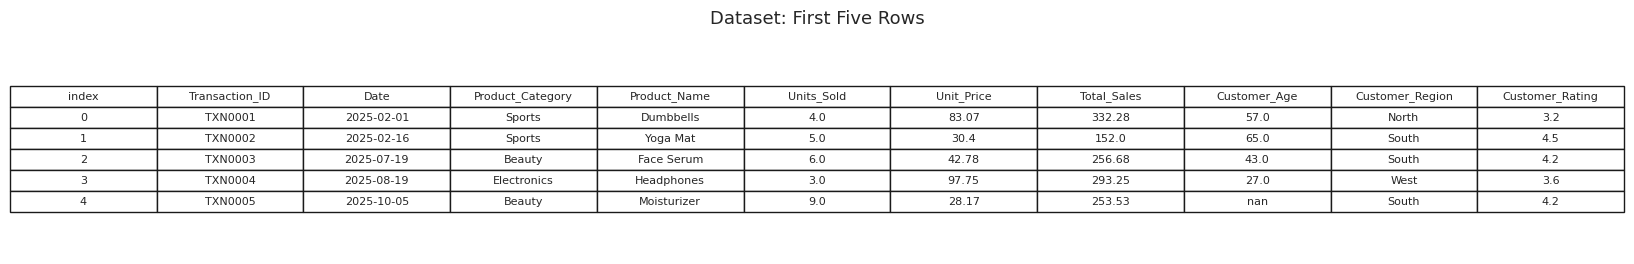

In [2]:
product_catalog = {
    "Electronics": {"Headphones": 89, "Smartwatch": 225, "Speaker": 120, "Tablet": 410},
    "Clothing": {"T-Shirt": 24, "Jeans": 62, "Jacket": 110, "Sneakers": 95},
    "Home": {"Lamp": 48, "Blender": 82, "Storage Box": 25, "Vacuum": 185},
    "Sports": {"Yoga Mat": 28, "Basketball": 35, "Dumbbells": 75, "Running Shoes": 115},
    "Beauty": {"Shampoo": 17, "Moisturizer": 26, "Sunscreen": 19, "Face Serum": 39}
}
categories = list(product_catalog)
rows = []
for transaction_id in range(1, 501):
    category = rng.choice(categories, p=[0.23, 0.25, 0.18, 0.20, 0.14])
    product = rng.choice(list(product_catalog[category]))
    price = round(float(product_catalog[category][product] * rng.uniform(0.85, 1.15)), 2)
    units = int(rng.integers(1, 10))
    date = pd.Timestamp("2025-01-01") + pd.Timedelta(days=int(rng.integers(0,365)))
    rows.append({"Transaction_ID":f"TXN{transaction_id:04d}", "Date":date,
                 "Product_Category":category, "Product_Name":product,
                 "Units_Sold":units, "Unit_Price":price,
                 "Total_Sales":round(units*price,2),
                 "Customer_Age":int(rng.integers(18,75)),
                 "Customer_Region":rng.choice(["North","South","East","West"]),
                 "Customer_Rating":round(float(np.clip(rng.normal(4.0, 0.6),1,5)),1)})
raw_generated = pd.DataFrame(rows)

# Intentionally add eight exceptionally large quantities to illustrate outliers.
large_purchase_rows = rng.choice(raw_generated.index, size=8, replace=False)
raw_generated.loc[large_purchase_rows, "Units_Sold"] *= rng.integers(7, 15, size=8)

# Select independent row sets for each missingness demonstration.
missing_plan = {"Units_Sold":10, "Unit_Price":10, "Customer_Age":12,
                "Customer_Region":10, "Customer_Rating":12, "Product_Category":8}
for col, count in missing_plan.items():
    idx = rng.choice(raw_generated.index, size=count, replace=False)
    raw_generated.loc[idx, col] = np.nan

# Recalculate derived values; do not leave apparently valid sales totals where a source is missing.
raw_generated["Total_Sales"] = (raw_generated["Units_Sold"] * raw_generated["Unit_Price"]).round(2)
raw_generated.to_csv(DATA_DIR / "retail_sales_raw.csv", index=False)

df_raw = pd.read_csv(DATA_DIR / "retail_sales_raw.csv", parse_dates=["Date"])
print("SCREENSHOT 01 — First five rows")
display(df_raw.head())
print("Shape:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())
print("Data types:")
print(df_raw.dtypes.to_string())
save_table(df_raw.head(), "01_dataset_preview.png", "Dataset: First Five Rows", 5)

## Step 2 — Data visualization

To avoid comparing incomplete records, each chart drops missing values **only in the columns necessary for that chart**. Consequently, charts may have slightly different sample sizes. Sales charts use the raw data before outlier removal to help visualize unusually large transactions. Monthly totals are observational fluctuations in generated data, not evidence of genuine seasonality.

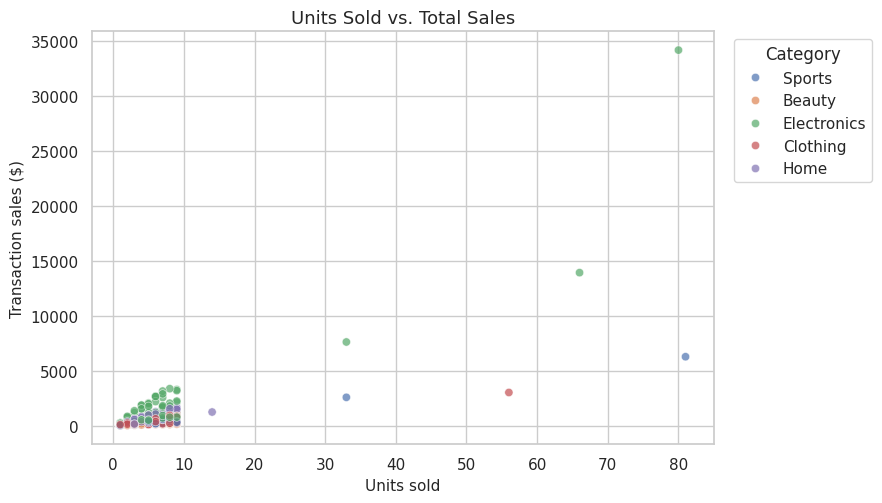

**Scatter insight:** Across 472 complete transactions, quantity and sales have Pearson correlation **0.75**. Transaction value also depends on unit price, so purchases with equal quantities can have different totals.

In [3]:
# Scatter plot: quantity versus revenue.
plot_df = df_raw.dropna(subset=["Units_Sold", "Total_Sales", "Product_Category"])
fig, ax = plt.subplots()
sns.scatterplot(data=plot_df, x="Units_Sold", y="Total_Sales", hue="Product_Category", alpha=.7, ax=ax)
ax.set(title="Units Sold vs. Total Sales", xlabel="Units sold", ylabel="Transaction sales ($)")
ax.legend(title="Category", bbox_to_anchor=(1.02,1), loc="upper left")
save_chart("02_scatter_plot.png")
r = plot_df[["Units_Sold","Total_Sales"]].corr().iloc[0,1]
display(Markdown(f"**Scatter insight:** Across {len(plot_df)} complete transactions, quantity and sales have Pearson correlation **{r:.2f}**. Transaction value also depends on unit price, so purchases with equal quantities can have different totals."))

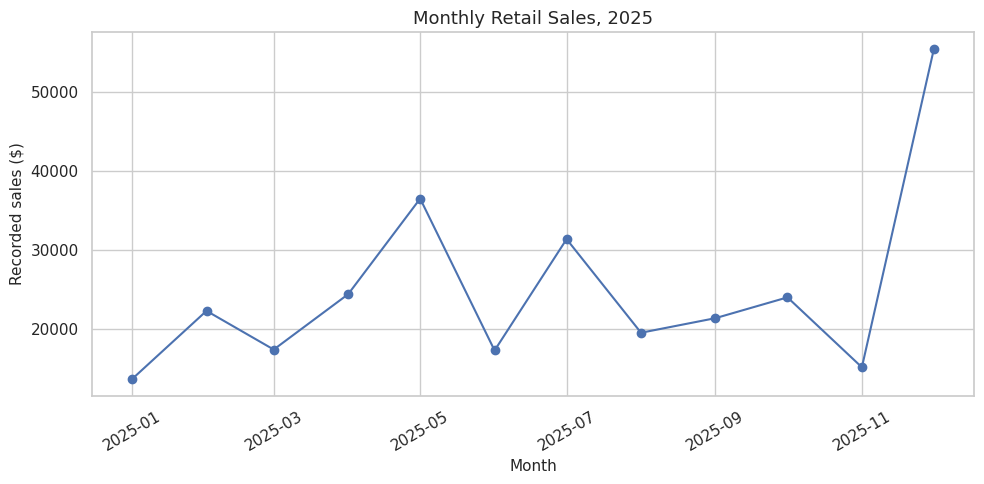

**Line insight:** The highest recorded monthly revenue is **December ($55,402.16)**, and the lowest is **January ($13,607.22)**. Because transaction dates and values were generated randomly, these variations should not be interpreted as real-world seasonality.

In [4]:
# Line chart: total sales by month.
monthly = (df_raw.dropna(subset=["Total_Sales"]).set_index("Date")
           .resample("MS")["Total_Sales"].sum())
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(monthly.index, monthly.values, marker="o")
ax.set(title="Monthly Retail Sales, 2025", xlabel="Month", ylabel="Recorded sales ($)")
ax.tick_params(axis="x", rotation=30)
save_chart("03_line_plot.png")
hi_month, lo_month = monthly.idxmax(), monthly.idxmin()
display(Markdown(f"**Line insight:** The highest recorded monthly revenue is **{hi_month:%B} (${monthly.max():,.2f})**, and the lowest is **{lo_month:%B} (${monthly.min():,.2f})**. Because transaction dates and values were generated randomly, these variations should not be interpreted as real-world seasonality."))

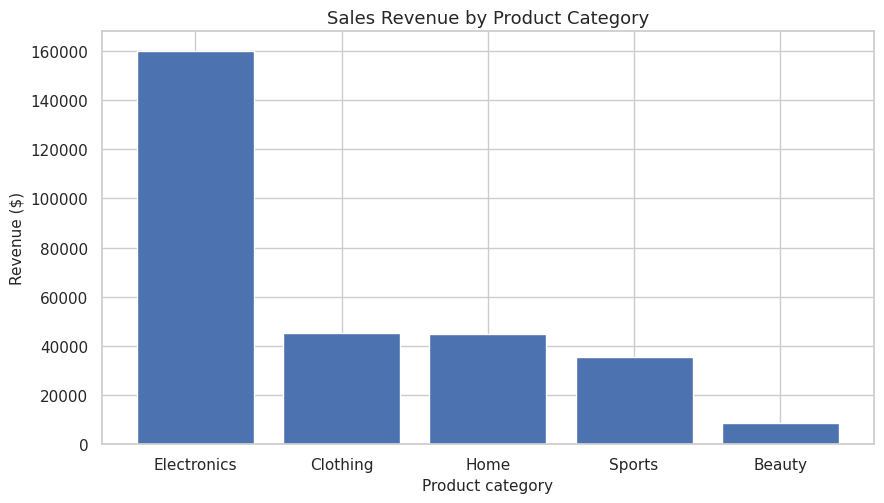

**Bar insight:** **Electronics** leads observed revenue ($160,016.22), while **Beauty** is lowest ($8,755.54). This reflects both transaction volume and item prices in the generated dataset.

In [5]:
# Bar chart: sum of transaction sales by category.
category_sales = (df_raw.dropna(subset=["Product_Category","Total_Sales"])
                  .groupby("Product_Category")["Total_Sales"].sum().sort_values(ascending=False))
fig, ax = plt.subplots()
ax.bar(category_sales.index, category_sales.values)
ax.set(title="Sales Revenue by Product Category", xlabel="Product category", ylabel="Revenue ($)")
save_chart("04_bar_chart.png")
display(Markdown(f"**Bar insight:** **{category_sales.index[0]}** leads observed revenue (${category_sales.iloc[0]:,.2f}), while **{category_sales.index[-1]}** is lowest (${category_sales.iloc[-1]:,.2f}). This reflects both transaction volume and item prices in the generated dataset."))

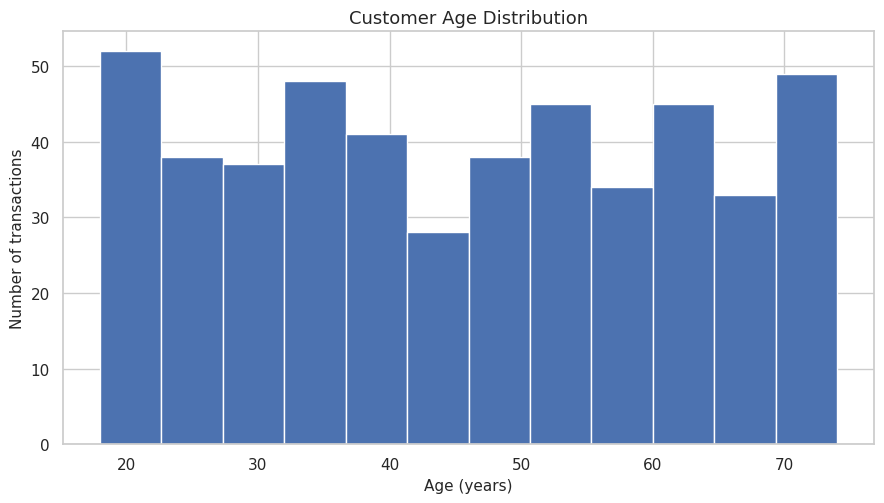

**Histogram insight:** Observed ages span **18–74** years, with a median of **45.5** years across 488 nonmissing records. This is a synthetic age profile, not a population estimate.

In [6]:
# Histogram: customer age distribution.
ages = df_raw["Customer_Age"].dropna()
fig, ax = plt.subplots()
ax.hist(ages, bins=12, edgecolor="white")
ax.set(title="Customer Age Distribution", xlabel="Age (years)", ylabel="Number of transactions")
save_chart("05_histogram.png")
display(Markdown(f"**Histogram insight:** Observed ages span **{int(ages.min())}–{int(ages.max())}** years, with a median of **{ages.median():.1f}** years across {len(ages)} nonmissing records. This is a synthetic age profile, not a population estimate."))

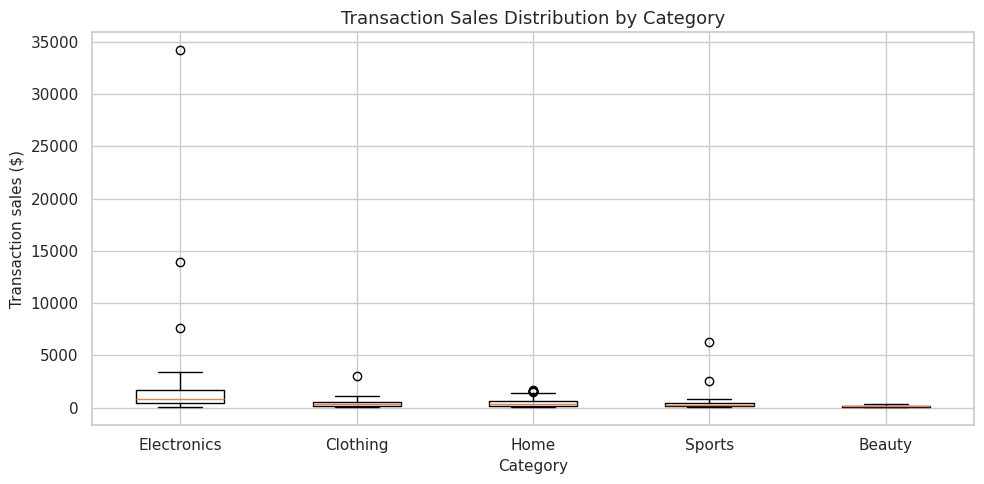

**Box-plot insight:** **Electronics** has the highest median transaction value ($780.15). Individual points beyond whiskers suggest unusually large transactions; they are not automatically data errors.

In [7]:
# Box plot: spread and potential outliers by category.
box_df = df_raw.dropna(subset=["Product_Category","Total_Sales"])
fig, ax = plt.subplots(figsize=(10,5))
ax.boxplot([box_df.loc[box_df["Product_Category"] == x, "Total_Sales"] for x in categories], tick_labels=categories)
ax.set(title="Transaction Sales Distribution by Category", xlabel="Category", ylabel="Transaction sales ($)")
save_chart("06_box_plot.png")
medians = box_df.groupby("Product_Category")["Total_Sales"].median().sort_values(ascending=False)
display(Markdown(f"**Box-plot insight:** **{medians.index[0]}** has the highest median transaction value (${medians.iloc[0]:,.2f}). Individual points beyond whiskers suggest unusually large transactions; they are not automatically data errors."))

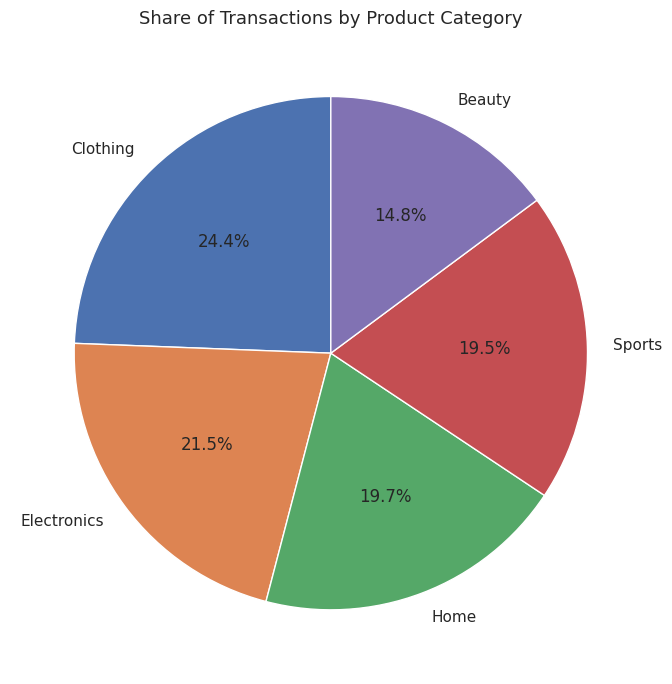

**Pie insight:** **Clothing** represents the largest share of transactions (**24.4%** of records with known categories). Transaction share is distinct from revenue share.

In [8]:
# Pie chart: counts rather than sales amounts.
category_counts = df_raw["Product_Category"].value_counts(dropna=True)
fig, ax = plt.subplots(figsize=(7,7))
ax.pie(category_counts, labels=category_counts.index, autopct="%1.1f%%", startangle=90)
ax.set_title("Share of Transactions by Product Category")
save_chart("07_pie_chart.png")
display(Markdown(f"**Pie insight:** **{category_counts.index[0]}** represents the largest share of transactions (**{category_counts.iloc[0] / category_counts.sum():.1%}** of records with known categories). Transaction share is distinct from revenue share."))

## Step 3 — Data preprocessing

Data cleaning follows a fixed order: (1) inspect and impute missing values; (2) enforce the arithmetic relationship for sales; (3) identify IQR outliers; (4) create reduced and transformed **copies**. The saved raw CSV is never overwritten.

### 3.1 Missing values

SCREENSHOT 08 — Missing counts and sample rows BEFORE treatment


,Before,Before %
Transaction_ID,0,0.0
Date,0,0.0
Product_Category,8,1.6
Product_Name,0,0.0
Units_Sold,10,2.0
Unit_Price,10,2.0
Total_Sales,20,4.0
Customer_Age,12,2.4
Customer_Region,10,2.0
Customer_Rating,12,2.4


,Transaction_ID,Date,Product_Category,Product_Name,Units_Sold,Unit_Price,Total_Sales,Customer_Age,Customer_Region,Customer_Rating
4,TXN0005,2025-10-05,Beauty,Moisturizer,9.0,28.17,253.53,NaN,South,4.2
14,TXN0015,2025-12-30,Sports,Yoga Mat,6.0,30.38,182.28,55.0,NaN,4.3
19,TXN0020,2025-04-10,Sports,Running Shoes,7.0,113.25,792.75,22.0,NaN,3.8
26,TXN0027,2025-12-15,Home,Storage Box,5.0,23.25,116.25,36.0,East,NaN
28,TXN0029,2025-03-31,Electronics,Speaker,7.0,112.12,784.84,55.0,East,NaN
30,TXN0031,2025-12-18,Clothing,Jeans,8.0,67.73,541.84,NaN,North,4.2
37,TXN0038,2025-09-05,Electronics,Headphones,1.0,NaN,NaN,73.0,North,4.0
45,TXN0046,2025-06-15,Home,Blender,NaN,91.04,NaN,48.0,North,3.2


SCREENSHOT 08 — Missing counts AFTER treatment


,Before,Before %,After
Transaction_ID,0,0.0,0
Date,0,0.0,0
Product_Category,8,1.6,0
Product_Name,0,0.0,0
Units_Sold,10,2.0,0
Unit_Price,10,2.0,0
Total_Sales,20,4.0,0
Customer_Age,12,2.4,0
Customer_Region,10,2.0,0
Customer_Rating,12,2.4,0


All missing values resolved: True


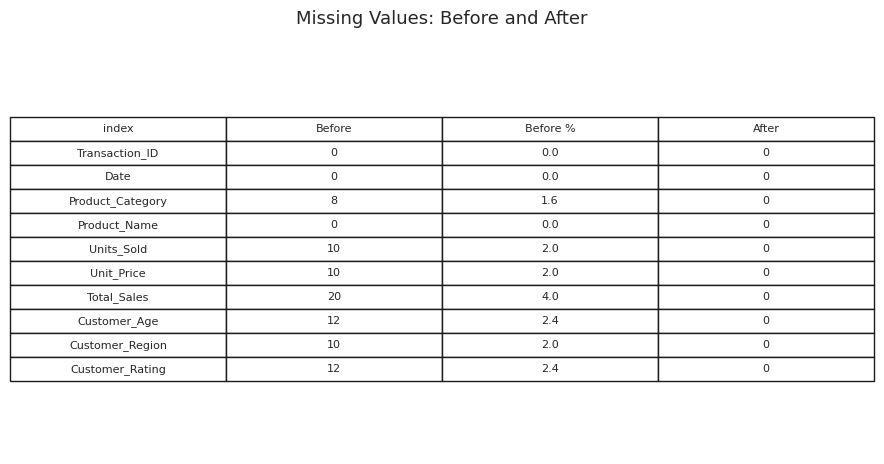

**Interpretation:** The raw data contain **82 missing cells** (including derived sales values). Median imputation reduces sensitivity to extreme values in numeric fields, while mode imputation uses the most frequent category. All missing cells are resolved after recalculating sales. These imputations are convenient for this demonstration but may distort relationships in real data.

In [9]:
missing_before = df_raw.isna().sum().rename("Before")
missing_pct = (df_raw.isna().mean()*100).round(1).rename("Before %")
print("SCREENSHOT 08 — Missing counts and sample rows BEFORE treatment")
display(pd.concat([missing_before,missing_pct],axis=1))
display(df_raw[df_raw.isna().any(axis=1)].head(8))

df_imputed = df_raw.copy()
for name in ["Units_Sold","Unit_Price","Customer_Age","Customer_Rating"]:
    df_imputed[name] = df_imputed[name].fillna(df_imputed[name].median())
for name in ["Product_Category","Customer_Region"]:
    df_imputed[name] = df_imputed[name].fillna(df_imputed[name].mode().iloc[0])
# Quantity and customer age represent whole numbers.
df_imputed["Units_Sold"] = df_imputed["Units_Sold"].round().astype(int)
df_imputed["Customer_Age"] = df_imputed["Customer_Age"].round().astype(int)
df_imputed["Total_Sales"] = (df_imputed["Units_Sold"] * df_imputed["Unit_Price"]).round(2)
missing_after = df_imputed.isna().sum().rename("After")
missing_comparison = pd.concat([missing_before,missing_pct,missing_after],axis=1)
print("SCREENSHOT 08 — Missing counts AFTER treatment")
display(missing_comparison)
print("All missing values resolved:", not df_imputed.isna().any().any())
save_table(missing_comparison, "08_missing_values.png", "Missing Values: Before and After")
display(Markdown(f"**Interpretation:** The raw data contain **{missing_before.sum()} missing cells** (including derived sales values). Median imputation reduces sensitivity to extreme values in numeric fields, while mode imputation uses the most frequent category. All missing cells are resolved after recalculating sales. These imputations are convenient for this demonstration but may distort relationships in real data."))

### 3.2 Outlier detection and removal (IQR)

For `Total_Sales`, the IQR rule marks values outside \(Q_1 - 1.5\times IQR\) and \(Q_3 + 1.5\times IQR\). The rule is simple and robust to extreme values, but a high-value purchase may be legitimate, particularly when categories have very different prices. Outliers are removed **only from a working copy** for this lab.

SCREENSHOT 09 — IQR calculations, flagged records, and row counts
Q1: $138.15; Q3: $637.37; IQR: $499.22
Lower fence: $-610.67; Upper fence: $1,386.19
Flagged: 40; before: 500; after: 460


,Transaction_ID,Product_Category,Units_Sold,Unit_Price,Total_Sales
5,TXN0006,Electronics,9,237.36,2136.24
16,TXN0017,Electronics,5,367.23,1836.15
31,TXN0032,Home,9,171.46,1543.14
41,TXN0042,Home,8,192.44,1539.52
54,TXN0055,Electronics,5,411.75,2058.75
58,TXN0059,Home,8,193.47,1547.76
76,TXN0077,Electronics,6,447.08,2682.48
80,TXN0081,Sports,81,77.51,6278.31
112,TXN0113,Home,9,183.06,1647.54
145,TXN0146,Electronics,7,366.18,2563.26


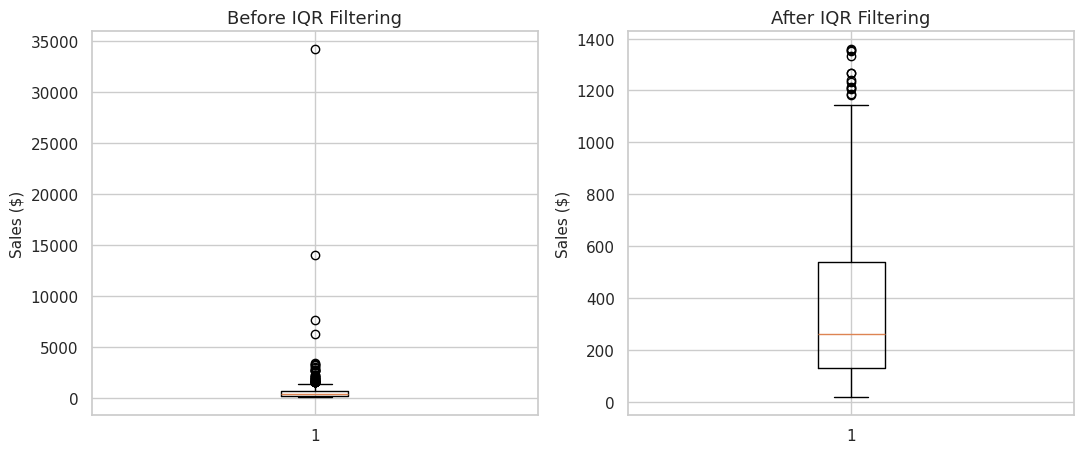

**Interpretation:** The IQR filter identifies and removes **40** of 500 records (**8.0%**). This reduces extreme transaction values but may also exclude legitimate high-value purchases. The cleaned dataset contains **460** rows.

In [10]:
q1 = df_imputed["Total_Sales"].quantile(.25)
q3 = df_imputed["Total_Sales"].quantile(.75)
iqr = q3-q1
lower = q1-1.5*iqr
upper = q3+1.5*iqr
outlier_mask = ~df_imputed["Total_Sales"].between(lower, upper)
outliers = df_imputed.loc[outlier_mask].copy()
df_clean = df_imputed.loc[~outlier_mask].copy()
print("SCREENSHOT 09 — IQR calculations, flagged records, and row counts")
print(f"Q1: ${q1:,.2f}; Q3: ${q3:,.2f}; IQR: ${iqr:,.2f}")
print(f"Lower fence: ${lower:,.2f}; Upper fence: ${upper:,.2f}")
print(f"Flagged: {len(outliers)}; before: {len(df_imputed)}; after: {len(df_clean)}")
display(outliers[["Transaction_ID","Product_Category","Units_Sold","Unit_Price","Total_Sales"]].head(20))
fig, axes = plt.subplots(1,2,figsize=(11,4.7))
axes[0].boxplot(df_imputed["Total_Sales"]);axes[0].set(title="Before IQR Filtering",ylabel="Sales ($)")
axes[1].boxplot(df_clean["Total_Sales"]);axes[1].set(title="After IQR Filtering",ylabel="Sales ($)")
save_chart("09_outlier_detection.png")
assert df_clean["Total_Sales"].notna().all()
assert np.allclose(df_clean["Total_Sales"], (df_clean["Units_Sold"]*df_clean["Unit_Price"]).round(2))
df_clean.to_csv(DATA_DIR / "retail_sales_cleaned.csv",index=False)
display(Markdown(f"**Interpretation:** The IQR filter identifies and removes **{len(outliers)}** of {len(df_imputed)} records (**{len(outliers)/len(df_imputed):.1%}**). This reduces extreme transaction values but may also exclude legitimate high-value purchases. The cleaned dataset contains **{len(df_clean)}** rows."))

### 3.3 Data reduction

Sampling reduces the number of rows; feature elimination reduces columns. `Transaction_ID` is an identifier, and `Product_Name` is redundant for broader category-level comparisons, although both could matter for other research questions.

SCREENSHOT 10 — Reduction before and after


,Measure,Before,After
0,Rows,460,230
1,Columns,10,8


Before — sample rows:


,Transaction_ID,Date,Product_Category,Product_Name,Units_Sold,Unit_Price,Total_Sales,Customer_Age,Customer_Region,Customer_Rating
0,TXN0001,2025-02-01,Sports,Dumbbells,4,83.07,332.28,57,North,3.2
1,TXN0002,2025-02-16,Sports,Yoga Mat,5,30.40,152.00,65,South,4.5
2,TXN0003,2025-07-19,Beauty,Face Serum,6,42.78,256.68,43,South,4.2


After sampling — sample rows:


,Transaction_ID,Date,Product_Category,Product_Name,Units_Sold,Unit_Price,Total_Sales,Customer_Age,Customer_Region,Customer_Rating
133,TXN0134,2025-01-01,Clothing,T-Shirt,2,23.40,46.80,34,North,3.4
33,TXN0034,2025-10-09,Home,Vacuum,1,174.78,174.78,37,East,4.7
216,TXN0217,2025-09-30,Clothing,Jeans,7,63.24,442.68,49,South,5.0


Columns before: ['Transaction_ID', 'Date', 'Product_Category', 'Product_Name', 'Units_Sold', 'Unit_Price', 'Total_Sales', 'Customer_Age', 'Customer_Region', 'Customer_Rating']
Columns after: ['Date', 'Product_Category', 'Units_Sold', 'Unit_Price', 'Total_Sales', 'Customer_Age', 'Customer_Region', 'Customer_Rating']


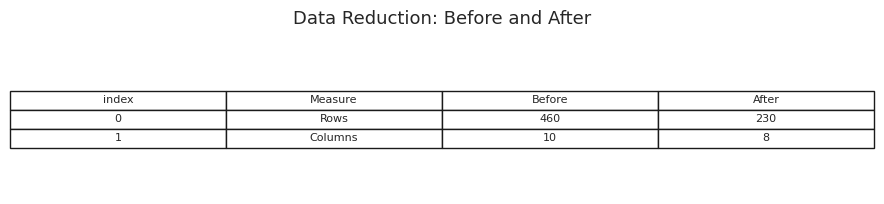

**Interpretation:** Sampling retains **230 of 460** cleaned transactions; removing two columns leaves **8** fields for analysis. A random sample supports quick exploration but can lose uncommon patterns.

In [11]:
sampled = df_clean.sample(frac=.50, random_state=42)
reduced = df_clean.drop(columns=["Transaction_ID","Product_Name"])
reduction_summary = pd.DataFrame({"Measure":["Rows","Columns"], "Before":[len(df_clean),df_clean.shape[1]],
                                  "After":[len(sampled),reduced.shape[1]]})
print("SCREENSHOT 10 — Reduction before and after")
display(reduction_summary)
print("Before — sample rows:");display(df_clean.head(3))
print("After sampling — sample rows:");display(sampled.head(3))
print("Columns before:",df_clean.columns.tolist())
print("Columns after:",reduced.columns.tolist())
save_table(reduction_summary, "10_data_reduction.png", "Data Reduction: Before and After")
display(Markdown(f"**Interpretation:** Sampling retains **{len(sampled)} of {len(df_clean)}** cleaned transactions; removing two columns leaves **{reduced.shape[1]}** fields for analysis. A random sample supports quick exploration but can lose uncommon patterns."))

### 3.4 Data scaling and discretization

Min-Max scaling transforms each selected numeric field using \((x-\min)/(\max-\min)\) to place it in the range 0 to 1. Discretization converts continuous customer ages into interpretable age groups. These transformations are demonstrated separately; statistics below use the unscaled cleaned data.

SCREENSHOT 11 — Original and scaled values


,Customer_Age,Units_Sold,Total_Sales,Customer_Age_Scaled,Units_Sold_Scaled,Total_Sales_Scaled
0,57,4,332.28,0.696,0.231,0.235
1,65,5,152.00,0.839,0.308,0.101
2,43,6,256.68,0.446,0.385,0.179
3,27,3,293.25,0.161,0.154,0.206
4,46,9,253.53,0.500,0.615,0.177
6,25,5,108.80,0.125,0.308,0.069
7,53,2,68.68,0.625,0.077,0.039
8,34,8,270.56,0.286,0.538,0.189
9,62,8,818.16,0.786,0.538,0.597
10,25,5,382.75,0.125,0.308,0.273


SCREENSHOT 11 — Continuous age and discretized category


,Customer_Age,Age_Group
0,57,Middle Aged (45-59)
1,65,Senior (60+)
2,43,Adult (30-44)
3,27,Young Adult (18-29)
4,46,Middle Aged (45-59)
6,25,Young Adult (18-29)
7,53,Middle Aged (45-59)
8,34,Adult (30-44)
9,62,Senior (60+)
10,25,Young Adult (18-29)


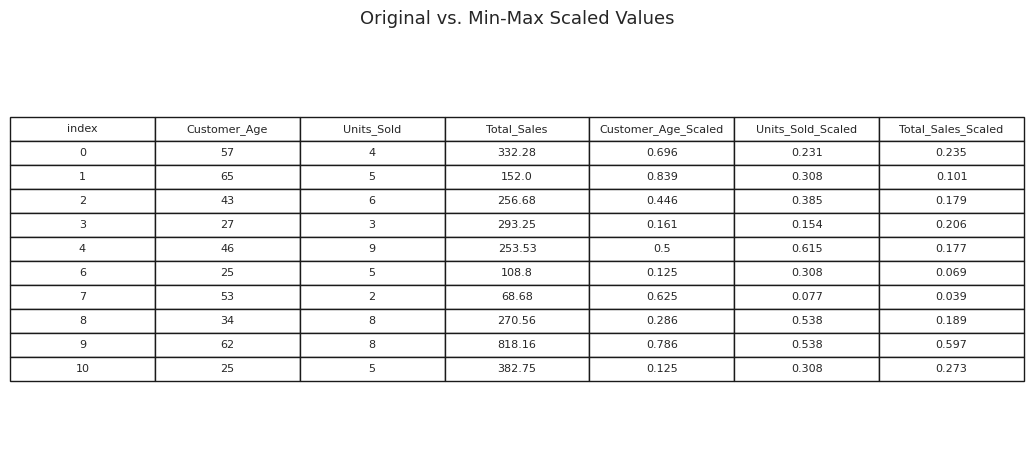

Age group counts:  Age_Group
Young Adult (18-29)    100
Adult (30-44)          112
Middle Aged (45-59)    127
Senior (60+)           121


In [12]:
scale_cols = ["Customer_Age","Units_Sold","Total_Sales"]
scaler = MinMaxScaler()
scaled_values = scaler.fit_transform(df_clean[scale_cols])
scaled = pd.DataFrame(scaled_values,columns=[f"{x}_Scaled" for x in scale_cols],index=df_clean.index)
scale_compare = pd.concat([df_clean[scale_cols],scaled],axis=1).head(10).round(3)
with_age_group = df_clean.copy()
with_age_group["Age_Group"] = pd.cut(with_age_group["Customer_Age"],
    bins=[18,30,45,60,np.inf],right=False,
    labels=["Young Adult (18-29)","Adult (30-44)","Middle Aged (45-59)","Senior (60+)"])
print("SCREENSHOT 11 — Original and scaled values")
display(scale_compare)
print("SCREENSHOT 11 — Continuous age and discretized category")
display(with_age_group[["Customer_Age","Age_Group"]].head(15))
assert scaled.ge(-1e-10).all().all() and scaled.le(1+1e-10).all().all()
assert with_age_group["Age_Group"].notna().all()
save_table(scale_compare, "11_scaling_discretization.png", "Original vs. Min-Max Scaled Values", 10)
print("Age group counts: ", with_age_group["Age_Group"].value_counts(sort=False).to_string())

## Step 4 — Statistical analysis

The statistics below use **`df_clean`**, the imputed, outlier-filtered data **before** sampling, scaling, and age-group creation. Pandas variance and standard deviation use sample formulas (`ddof=1`).

### 4.1 General overview

SCREENSHOT 12 — df_clean.info()
<class 'pandas.core.frame.DataFrame'>
Index: 460 entries, 0 to 499
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction_ID    460 non-null    object        
 1   Date              460 non-null    datetime64[ns]
 2   Product_Category  460 non-null    object        
 3   Product_Name      460 non-null    object        
 4   Units_Sold        460 non-null    int64         
 5   Unit_Price        460 non-null    float64       
 6   Total_Sales       460 non-null    float64       
 7   Customer_Age      460 non-null    int64         
 8   Customer_Region   460 non-null    object        
 9   Customer_Rating   460 non-null    float64       
dtypes: datetime64[ns](1), float64(3), int64(2), object(4)
memory usage: 39.5+ KB

SCREENSHOT 12 — df_clean.describe()


,Date,Units_Sold,Unit_Price,Total_Sales,Customer_Age,Customer_Rating
count,460,460.00,460.00,460.00,460.00,460.00
mean,2025-07-04 02:55:18.260869632,4.98,77.07,361.56,45.97,3.98
min,2025-01-01 00:00:00,1.00,15.14,16.01,18.00,1.80
25%,2025-03-31 00:00:00,3.00,27.92,129.65,33.00,3.60
50%,2025-07-07 00:00:00,5.00,68.23,259.09,46.00,4.00
75%,2025-10-02 00:00:00,7.00,99.70,537.68,60.00,4.30
max,2025-12-31 00:00:00,14.00,451.91,1360.72,74.00,5.00
std,NaN,2.64,63.21,300.94,16.56,0.54


SCREENSHOT 12 — df_clean.describe(include='all')


,Transaction_ID,Date,Product_Category,Product_Name,Units_Sold,Unit_Price,Total_Sales,Customer_Age,Customer_Region,Customer_Rating
count,460,460,460,460,460.000000,460.000000,460.000000,460.000000,460,460.000000
unique,460,NaN,5,20,NaN,NaN,NaN,NaN,4,NaN
top,TXN0001,NaN,Clothing,Jeans,NaN,NaN,NaN,NaN,East,NaN
freq,1,NaN,127,39,NaN,NaN,NaN,NaN,146,NaN
mean,NaN,2025-07-04 02:55:18.260869632,NaN,NaN,4.984783,77.067978,361.556043,45.971739,NaN,3.978261
min,NaN,2025-01-01 00:00:00,NaN,NaN,1.000000,15.140000,16.010000,18.000000,NaN,1.800000
25%,NaN,2025-03-31 00:00:00,NaN,NaN,3.000000,27.922500,129.650000,33.000000,NaN,3.600000
50%,NaN,2025-07-07 00:00:00,NaN,NaN,5.000000,68.230000,259.090000,46.000000,NaN,4.000000
75%,NaN,2025-10-02 00:00:00,NaN,NaN,7.000000,99.697500,537.680000,60.000000,NaN,4.300000
max,NaN,2025-12-31 00:00:00,NaN,NaN,14.000000,451.910000,1360.720000,74.000000,NaN,5.000000


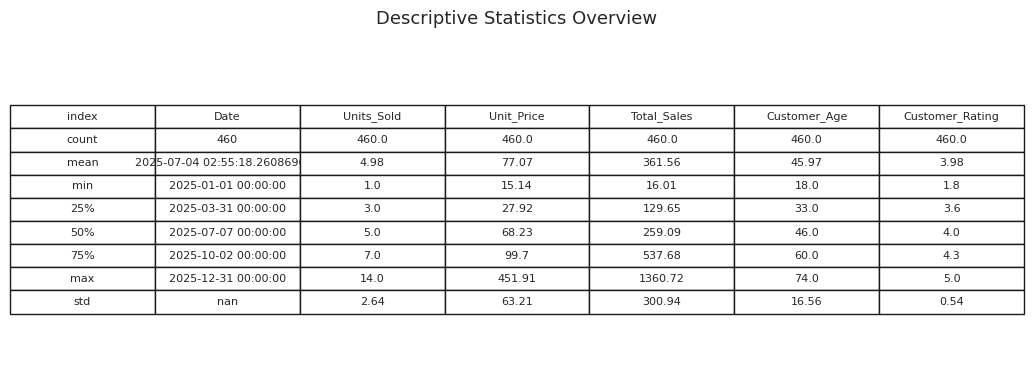

**Interpretation:** After cleaning, the dataset has **460 rows and 10 columns**, with **0 missing cells**. Numeric summaries report the center and spread of quantities, prices, ages, ratings, and transaction totals.

In [13]:
print("SCREENSHOT 12 — df_clean.info()")
buffer = io.StringIO();df_clean.info(buf=buffer);print(buffer.getvalue())
print("SCREENSHOT 12 — df_clean.describe()")
display(df_clean.describe().round(2))
print("SCREENSHOT 12 — df_clean.describe(include='all')")
display(df_clean.describe(include="all"))
save_table(df_clean.describe().round(2),"12_data_overview.png","Descriptive Statistics Overview")
display(Markdown(f"**Interpretation:** After cleaning, the dataset has **{df_clean.shape[0]} rows and {df_clean.shape[1]} columns**, with **{int(df_clean.isna().sum().sum())} missing cells**. Numeric summaries report the center and spread of quantities, prices, ages, ratings, and transaction totals."))

### 4.2 Central tendency

SCREENSHOT 13 — Central tendency table


,Minimum,Maximum,Mean,Median,Mode
Units_Sold,1.00,14.00,4.98,5.00,5.00
Unit_Price,15.14,451.91,77.07,68.23,72.52
Total_Sales,16.01,1360.72,361.56,259.09,72.52
Customer_Age,18.00,74.00,45.97,46.00,46.00
Customer_Rating,1.80,5.00,3.98,4.00,4.00


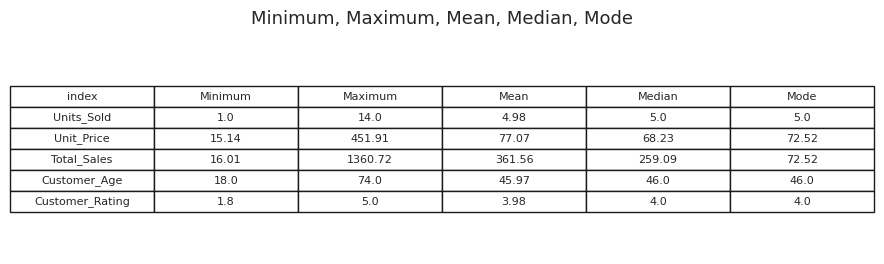

**Interpretation:** Mean transaction sales are **$361.56**, above the median of **$259.09**. The gap provides an indication of asymmetry, though a histogram or formal skewness statistic would be needed to describe the shape precisely.

In [14]:
numeric_data = df_clean.select_dtypes(include="number")
mode_vals = numeric_data.mode(dropna=True).iloc[0]
central = pd.DataFrame({"Minimum":numeric_data.min(),"Maximum":numeric_data.max(),
    "Mean":numeric_data.mean(),"Median":numeric_data.median(),"Mode":mode_vals}).round(2)
print("SCREENSHOT 13 — Central tendency table")
display(central)
save_table(central,"13_central_tendency.png","Minimum, Maximum, Mean, Median, Mode")
mean_sales = central.loc["Total_Sales","Mean"]
median_sales = central.loc["Total_Sales","Median"]
skew_desc = "above" if mean_sales>median_sales else "below" if mean_sales<median_sales else "equal to"
display(Markdown(f"**Interpretation:** Mean transaction sales are **${mean_sales:,.2f}**, {skew_desc} the median of **${median_sales:,.2f}**. The gap provides an indication of asymmetry, though a histogram or formal skewness statistic would be needed to describe the shape precisely."))

### 4.3 Dispersion

SCREENSHOT 14 — Dispersion measures


,Range,Q1,Q2 (Median),Q3,IQR,Variance,Std Dev
Units_Sold,13.00,3.00,5.00,7.00,4.00,6.96,2.64
Unit_Price,436.77,27.92,68.23,99.70,71.78,3996.13,63.21
Total_Sales,1344.71,129.65,259.09,537.68,408.03,90566.75,300.94
Customer_Age,56.00,33.00,46.00,60.00,27.00,274.35,16.56
Customer_Rating,3.20,3.60,4.00,4.30,0.70,0.29,0.54


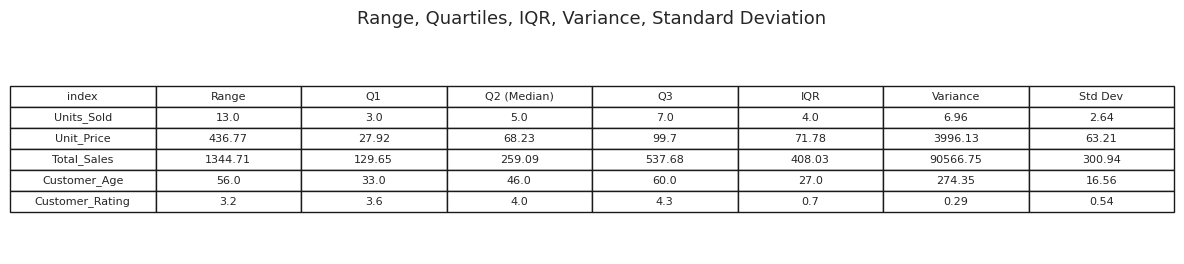

**Interpretation:** Cleaned sales have a range of **$1,344.71**, an IQR of **$408.03**, and a sample standard deviation of **$300.94**. These quantify transaction-value variability in dollars; variance is in squared dollars. It is not meaningful to compare raw variances across features with different units.

In [15]:
dispersion = pd.DataFrame(index=numeric_data.columns)
dispersion["Range"] = numeric_data.max()-numeric_data.min()
dispersion["Q1"] = numeric_data.quantile(.25)
dispersion["Q2 (Median)"] = numeric_data.quantile(.50)
dispersion["Q3"] = numeric_data.quantile(.75)
dispersion["IQR"] = dispersion["Q3"]-dispersion["Q1"]
dispersion["Variance"] = numeric_data.var(ddof=1)
dispersion["Std Dev"] = numeric_data.std(ddof=1)
dispersion = dispersion.round(2)
print("SCREENSHOT 14 — Dispersion measures")
display(dispersion)
save_table(dispersion,"14_dispersion.png","Range, Quartiles, IQR, Variance, Standard Deviation")
display(Markdown(f"**Interpretation:** Cleaned sales have a range of **${dispersion.loc['Total_Sales','Range']:,.2f}**, an IQR of **${dispersion.loc['Total_Sales','IQR']:,.2f}**, and a sample standard deviation of **${dispersion.loc['Total_Sales','Std Dev']:,.2f}**. These quantify transaction-value variability in dollars; variance is in squared dollars. It is not meaningful to compare raw variances across features with different units."))

### 4.4 Pearson correlation

SCREENSHOT 15 — Pearson correlation matrix


,Units_Sold,Unit_Price,Total_Sales,Customer_Age,Customer_Rating
Units_Sold,1.000,-0.136,0.509,-0.004,0.031
Unit_Price,-0.136,1.000,0.654,-0.001,-0.006
Total_Sales,0.509,0.654,1.000,-0.016,-0.033
Customer_Age,-0.004,-0.001,-0.016,1.000,-0.022
Customer_Rating,0.031,-0.006,-0.033,-0.022,1.000


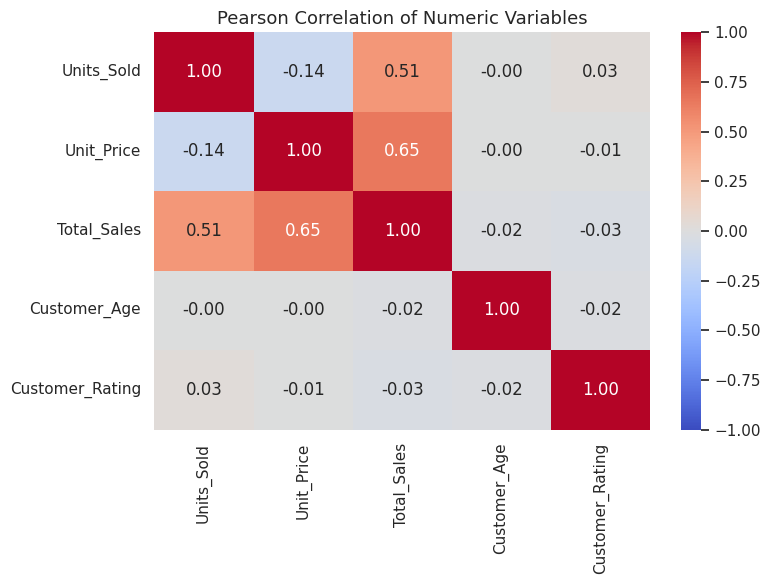

Top three unique pairwise correlations:


,Variable 1,Variable 2,Correlation
4,Unit_Price,Total_Sales,0.654
1,Units_Sold,Total_Sales,0.509
0,Units_Sold,Unit_Price,-0.136


**Interpretation:** The three strongest unique Pearson correlations are: - **Unit_Price vs. Total_Sales**: r = **+0.654** (positive relationship).; - **Units_Sold vs. Total_Sales**: r = **+0.509** (positive relationship).; - **Units_Sold vs. Unit_Price**: r = **-0.136** (negative relationship).. Because `Total_Sales` is calculated from price and quantity, related correlations are partly structural. **Correlation does not establish causation.**

In [16]:
corr = numeric_data.corr(method="pearson")
print("SCREENSHOT 15 — Pearson correlation matrix")
display(corr.round(3))
fig,ax = plt.subplots(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1,vmax=1, ax=ax)
ax.set_title("Pearson Correlation of Numeric Variables")
save_chart("15_correlation_matrix.png")
# Keep only unique off-diagonal pairs.
upper_triangle = np.triu(np.ones(corr.shape),k=1).astype(bool)
unique_pairs = (corr.where(upper_triangle).stack().rename("Correlation")
                .reset_index().rename(columns={"level_0":"Variable 1","level_1":"Variable 2"}))
unique_pairs["Absolute"] = unique_pairs["Correlation"].abs()
top3 = unique_pairs.sort_values("Absolute",ascending=False).head(3)
print("Top three unique pairwise correlations:")
display(top3.drop(columns="Absolute").round(3))
lines = [f"- **{row['Variable 1']} vs. {row['Variable 2']}**: r = **{row['Correlation']:+.3f}** ({'positive' if row['Correlation']>0 else 'negative'} relationship)." for _,row in top3.iterrows()]
display(Markdown("**Interpretation:** The three strongest unique Pearson correlations are: "+"; ".join(lines)+". Because `Total_Sales` is calculated from price and quantity, related correlations are partly structural. **Correlation does not establish causation.**"))

## Step 5 — Conclusion and key findings

The following summary is produced from the executed dataset so that the reported numbers always match the project files. The synthetic data demonstrate Python-based exploratory analysis and preprocessing; the findings are instructional rather than representative of genuine customers or market performance.

In [17]:
strongest = top3.iloc[0]
final_text = f"""Across **{len(df_raw)}** generated retail transactions, the analysis compared category revenue, monthly trends, customer ages, and transaction values using six types of visualizations. **{category_sales.index[0]}** produced the highest observed raw-data category revenue (**${category_sales.iloc[0]:,.2f}**). The busiest revenue month was **{hi_month:%B}** at **${monthly.max():,.2f}**, but this variation cannot establish seasonality because the data were randomly generated. The median recorded customer age was **{ages.median():.1f} years**.

Preprocessing addressed **{int(missing_before.sum())} missing cells**, using medians for numeric values and modes for categories, followed by recalculation of the sales field. The IQR method marked and removed **{len(outliers)}** unusually large transactions, leaving **{len(df_clean)}** complete observations. Sampling reduced this to **{len(sampled)}** example observations; removing identifier/product-level columns, Min-Max scaling, and age discretization illustrated alternative data representations. The observed mean and median cleaned transaction values were **${mean_sales:,.2f}** and **${median_sales:,.2f}**.

The strongest observed unique numerical correlation was **{strongest['Variable 1']} versus {strongest['Variable 2']} (r = {strongest['Correlation']:+.3f})**. This association should not be treated as causal, especially because sales are mathematically derived from quantity and price. Overall, the lab shows how descriptive statistics and preprocessing can make a dataset easier to inspect and prepare for subsequent data mining. Its key limitation is that the transactions are synthetic, and deleting IQR outliers may remove legitimate high-value purchases in real sales data."""
display(Markdown(final_text))
print("Validation checks:")
print("Raw rows:",len(df_raw),"Clean rows:",len(df_clean),"Missing after cleaning:",df_clean.isna().sum().sum())
print("Sales arithmetic valid:",np.allclose(df_clean["Total_Sales"],(df_clean["Units_Sold"]*df_clean["Unit_Price"]).round(2)))
assert len(df_raw)==500 and len(df_clean)>0 and df_clean.isna().sum().sum()==0

Across **500** generated retail transactions, the analysis compared category revenue, monthly trends, customer ages, and transaction values using six types of visualizations. **Electronics** produced the highest observed raw-data category revenue (**$160,016.22**). The busiest revenue month was **December** at **$55,402.16**, but this variation cannot establish seasonality because the data were randomly generated. The median recorded customer age was **45.5 years**.

Preprocessing addressed **82 missing cells**, using medians for numeric values and modes for categories, followed by recalculation of the sales field. The IQR method marked and removed **40** unusually large transactions, leaving **460** complete observations. Sampling reduced this to **230** example observations; removing identifier/product-level columns, Min-Max scaling, and age discretization illustrated alternative data representations. The observed mean and median cleaned transaction values were **$361.56** and **$259.09**.

The strongest observed unique numerical correlation was **Unit_Price versus Total_Sales (r = +0.654)**. This association should not be treated as causal, especially because sales are mathematically derived from quantity and price. Overall, the lab shows how descriptive statistics and preprocessing can make a dataset easier to inspect and prepare for subsequent data mining. Its key limitation is that the transactions are synthetic, and deleting IQR outliers may remove legitimate high-value purchases in real sales data.

Validation checks:
Raw rows: 500 Clean rows: 460 Missing after cleaning: 0
Sales arithmetic valid: True


## Submission screenshot checklist

The `screenshots/` directory automatically receives 15 named **chart/table evidence images**. If the instructor expects literal screenshots of notebook output cells, capture those outputs in VS Code rather than relying exclusively on the generated PNGs.

- `01_dataset_preview.png`: `.head()` output
- `02`–`07`: six plots, with notebook insight underneath each
- `08_missing_values.png`: missing-value table **plus capture the before/after notebook output**
- `09_outlier_detection.png`: before/after boxplots **plus capture Q1, Q3, IQR, bounds, and flagged rows**
- `10_data_reduction.png`: counts **plus capture sample rows and column lists**
- `11_scaling_discretization.png`: scaling **plus capture age-group output**
- `12_data_overview.png`: statistics table **plus capture `.info()` and `.describe()` output**
- `13_central_tendency.png`: calculations
- `14_dispersion.png`: calculations
- `15_correlation_matrix.png`: heatmap **plus capture numerical matrix**

When finished, commit the `.ipynb`, both CSVs, `README.md`, `requirements.txt`, and screenshot evidence to a **public GitHub repository** named `MSCS_634_Lab_1`. Do not commit `.venv/`.